# Data Science: Course Assignment 1

The company "Urban Trends" is a rising start in the retail industry, focusing on a wide range of products from electronics to fashion and home goods. Being founded in Denmark the company quickly extended into multiple cities accross the country and abroad, building up presence through different retail stores. To keep their stores stocked and their supply chain running smoothly Urban Trends has partnered with a variety of suppliers.

Over the past few years the company has collected valuable sales data but struggled to extract any actionable insights from it. For example, Urban Trends would like to optimise their product offerings, improve their inventory levels and understand their customer better.

As a data scientist your role is to extract any valueable insights from the provided data, uncovering patterns, trends, inefficiencies and finally provide recommendations to improve Urban Trends' operations. For this you are provided with two datasets.

### Product Dataset Description
The product dataset contains all the different products Urban Trends is selling accross their stores:
- **SKU**: The stock keeping unit (SKU) is a unique code that is assigned to a product to track its sales, inventory, etc.
- **Product Name**: The name of the product.
- **Product Family**: The category that the product is placed in.
- **Sale Price**: The net price that the product is sold for (in DKK). The price is consistent across all stores and locations.
- **COGS**: The cost of goods sold (COGS) are the costs assiciated with selling the product (in DKK). The COGS is consistent across all stores and locations.
- **Supplier**: The name of the supplier that delivers the product. Note that some products can be acquired from multiple suppliers
- **Replenishment Time**: The time between ordering from the supplier until the delivery hits the store (in days).
- **Replenishment Frequency**: The time interval between placing individual orders (in days).

### Invoice Dataset Description
The invoice dataset contains all invoices across all stores that were generated over the past 2 years in daily frequency:
- **Invoive number**: Unique number associated with a single invoice. Note that an invoice can contain sales for multiple products.
- **Date**: The data at which the invoice was generated.
- **Store**: The store name at which the invoice was generated. Note that some stores are in multiple locations.
- **Store Location**: The location of the store at which the invoice was generated.
- **SKU**: The SKU of the product that was sold.
- **Quantity**: The amount of products that were sold.

### Tasks

1. Import product & invoice dataset
2. Clean dataset & check for outliers. How many have you found?
3. Measure central tendency, variability and distribution of sales for the product 'Socks (5-pack)' across all stores
4. Measure central tendency, variability and distribution of sales across stores in 'Copenhagen' across all products
5. Plot the data you got out of the previous tasks in an appropriate way
6. By performing EDA, which insigths can you get from the provided data?
7. Cluster the different product families in a graph comparing sales quantity vs. revenue
8. Calculate mean, standard deviation and coefficient of variation (CV) of the sales of the different product families. What can you learn about the demand patterns?

Submitted by group 10 in Data Science (E26): 
Participants in alphabetical order: 
- Anamika Kamal 
- Jakub Swierzko
- Klavs Zile
- Krzysztof Sekulski
- Md Ragib Shahriyear
- Saif Ur Rehman 



# 1. Import product & invoice dataset

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Markdown
import matplotlib.pyplot as plt

In [2]:
# importing the csv files with pandas

products_raw = pd.read_csv("data_products_10.csv")
invoices_raw = pd.read_csv("data_invoices_10.csv")

In [3]:
# checking out the product and invoices dataframes
print(products_raw.head(10))
print(invoices_raw.head(10))

   SKU     Product Name     Product Family  Sale Price              Supplier  \
0    7   Socks (5-pack)            Apparel         150     CozyWear Clothing   
1   27       Phone Case        Electronics         250        VoltWave Comm.   
2   29       HDMI Cable        Electronics         200        VoltWave Comm.   
3   36    Throw Blanket               Home         400  FloraRise Botanicals   
4   58  Hiking Backpack  Sports & Outdoors         800  PeakPerformance Gear   
5   58  Hiking Backpack  Sports & Outdoors         800          EcoAdventure   
6   63     Camping Tent  Sports & Outdoors         900          EcoAdventure   
7   71       Marker Set    Office Supplies          50      Deskify Supplies   
8  164      Pull-Up Bar  Fitness Equipment         150               FitZone   
9  189  Portable Heater  Tools & Machinery         450        Workforce Gear   

   COGS  Replenishment Time  Replenishment Frequency  Product Emissions  \
0    45                  10                 

In [4]:
# figuring out the number of rows and column in each dataset to get a better idea of the dataset size

print(f'Products: {products_raw.shape[0]:,} rows x {products_raw.shape[1]} columns')
print(f'Invoices: {invoices_raw.shape[0]:,} rows x {invoices_raw.shape[1]} columns')

Products: 11 rows x 11 columns
Invoices: 83,791 rows x 6 columns


In [5]:
# What are the unique values in product name, product family, and store location? because these will give us a better idea
# about the complete dataset


print('Products:', ', '.join(sorted(products_raw['Product Name'].unique())))
print('Families:', ', '.join(sorted(products_raw['Product Family'].unique())))
print('Locations:', ', '.join(sorted(invoices_raw['Store Location'].dropna().unique())))
display(invoices_raw[['Store', 'Store Location']].dropna().drop_duplicates().sort_values(['Store Location', 'Store']))

# checking out the date range by converting it to actual datetime datatype

raw_dates = pd.to_datetime(invoices_raw['Date'], errors='coerce')
print(f'Date range: {raw_dates.min():%Y-%m-%d} to {raw_dates.max():%Y-%m-%d}') 



Products: Camping Tent, Extension Cord, HDMI Cable, Hiking Backpack, Marker Set, Phone Case, Portable Heater, Pull-Up Bar, Socks (5-pack), Throw Blanket
Families: Apparel, Electronics, Fitness Equipment, Home, Office Supplies, Sports & Outdoors, Tools & Machinery
Locations: Copenhagen, Odense, Vejle


,Store,Store Location
5,Northern & Co.,Copenhagen
0,Strand & Co.,Copenhagen
27,TrendStop,Copenhagen
17,Nordic House,Odense
8,Prime Goods,Vejle


Date range: 2024-01-01 to 2025-12-31


# 2. Clean dataset & check for outliers. How many have you found?


checking for missing values:

In [6]:
display(pd.DataFrame({'Product missing values': products_raw.isna().sum(),
                      'Invoice missing values': invoices_raw.isna().sum()}).fillna(0).astype(int))

,Product missing values,Invoice missing values
COGS,0,0
Date,0,13
Invoice Number,0,18
Product Emissions,0,0
Product Family,0,0
Product Name,0,0
Replenishment Frequency,0,0
Replenishment Time,0,0
SKU,0,12
Sale Price,0,0


In [7]:
# checking for missing values and duplicates

raw_missing_rows = int(invoices_raw.isna().any(axis=1).sum())
raw_duplicate_excess = int(invoices_raw.duplicated().sum())

print(f'Raw invoice rows with a missing field: {raw_missing_rows:,}')
print(f'Extra exact duplicate invoice rows: {raw_duplicate_excess:,}')
print(f'Extra exact duplicate product rows: {products_raw.duplicated().sum():,}')

Raw invoice rows with a missing field: 85
Extra exact duplicate invoice rows: 84
Extra exact duplicate product rows: 0


In [8]:
# removing the duplicates

deduplicated = invoices_raw.drop_duplicates().copy()
missing_after_dedup = deduplicated.isna().any(axis=1)
candidate = deduplicated.loc[~missing_after_dedup].copy()

In [9]:
candidate['Date'] = pd.to_datetime(candidate['Date'], errors='coerce')

# selecting columns that are numeric


numeric_fields = ['Invoice Number', 'SKU', 'Sales Quantity']

Final data cleanup

In [10]:

for column in numeric_fields:
    candidate[column] = pd.to_numeric(candidate[column], errors='coerce')



numeric_valid = np.isfinite(candidate[numeric_fields]).all(axis=1)

integer_valid = candidate[numeric_fields].mod(1).eq(0).all(axis=1)

positive_valid = candidate[numeric_fields].gt(0).all(axis=1)

known_sku = candidate['SKU'].isin(products_raw['SKU'])



valid = numeric_valid & integer_valid & positive_valid & known_sku & candidate['Date'].notna()

invoices = candidate.loc[valid].copy()

invoices[numeric_fields] = invoices[numeric_fields].astype('int64')

for column in ['Store', 'Store Location']:
    invoices[column] = invoices[column].str.strip()
assert invoices[['Store', 'Store Location']].ne('').all().all()

cleaning_audit = pd.DataFrame({
    'Step': ['Original rows', 'Remove extra exact duplicates',
             'Exclude incomplete rows after deduplication', 'Exclude other invalid rows', 'Final usable rows'],
    'Rows': [len(invoices_raw), raw_duplicate_excess, int(missing_after_dedup.sum()),
             int((~valid).sum()), len(invoices)]
})

display(cleaning_audit)

assert len(invoices_raw) - cleaning_audit.loc[1:3, 'Rows'].sum() == len(invoices)

assert not invoices.duplicated(['Invoice Number', 'SKU']).any()

print('Final invoices:', invoices['Invoice Number'].nunique())

,Step,Rows
0,Original rows,83791
1,Remove extra exact duplicates,84
2,Exclude incomplete rows after deduplication,84
3,Exclude other invalid rows,0
4,Final usable rows,83623


Final invoices: 32152


In [11]:
''' SKU 58 has two suppliers, not two different products. 
The name, family, and sale price agree within each SKU, 
So we will build a unique lookup containing those fields only. 
A `many_to_one` merge guarantees that joining cannot multiply invoice rows, because that would be a problem. 
The catalogue contradicts its description for backpack COGS, 2 suppliers list different costs. 
Since an invoice does not identify the supplier, we will calculate a catalogue-based gross-profit range.
The higher cost will be its lower bound and the lower cost will be its upper bound. '''


products = products_raw.drop_duplicates().copy()


lookup_columns = ['SKU', 'Product Name', 'Product Family', 'Sale Price']
for column in lookup_columns[1:]:
    assert products.groupby('SKU')[column].nunique().eq(1).all(), f'Conflicting {column}'

product_numeric = ['Sale Price', 'COGS', 'Replenishment Time', 'Replenishment Frequency', 'Start Stock']

assert np.isfinite(products[product_numeric]).all().all()
assert products[product_numeric].ge(0).all().all()
assert products['Sale Price'].gt(0).all()
assert products['COGS'].le(products['Sale Price']).all()

product_lookup = products[lookup_columns].drop_duplicates('SKU')

cost_bounds = products.groupby('SKU')['COGS'].agg(COGS_min='min', COGS_max='max').reset_index()


product_lookup = product_lookup.merge(cost_bounds, on='SKU', validate='one_to_one')

sales = invoices.merge(product_lookup, on='SKU', how='left', validate='many_to_one', indicator=True)
assert len(sales) == len(invoices) and sales['_merge'].eq('both').all()

sales = sales.drop(columns='_merge')

sales['Revenue'] = sales['Sales Quantity'] * sales['Sale Price']

sales['Gross profit lower'] = sales['Sales Quantity'] * (sales['Sale Price'] - sales['COGS_max'])

sales['Gross profit upper'] = sales['Sales Quantity'] * (sales['Sale Price'] - sales['COGS_min'])

sales['Store ID'] = sales['Store'] + ' (' + sales['Store Location'] + ')'

display(products.loc[products.duplicated('SKU', keep=False)])

display(sales.head())

,SKU,Product Name,Product Family,Sale Price,Supplier,COGS,Replenishment Time,Replenishment Frequency,Product Emissions,Transportation Emissions,Start Stock
4,58,Hiking Backpack,Sports & Outdoors,800,PeakPerformance Gear,350,10,5,6.5,110,10
5,58,Hiking Backpack,Sports & Outdoors,800,EcoAdventure,400,14,6,4.8,75,10


,Invoice Number,Date,Store,Store Location,SKU,Sales Quantity,Product Name,Product Family,Sale Price,COGS_min,COGS_max,Revenue,Gross profit lower,Gross profit upper,Store ID
0,1,2024-01-01,Strand & Co.,Copenhagen,36,1,Throw Blanket,Home,400,120,120,400,280,280,Strand & Co. (Copenhagen)
1,1,2024-01-01,Strand & Co.,Copenhagen,58,1,Hiking Backpack,Sports & Outdoors,800,350,400,800,400,450,Strand & Co. (Copenhagen)
2,1,2024-01-01,Strand & Co.,Copenhagen,29,1,HDMI Cable,Electronics,200,50,50,200,150,150,Strand & Co. (Copenhagen)
3,1,2024-01-01,Strand & Co.,Copenhagen,189,1,Portable Heater,Tools & Machinery,450,180,180,450,270,270,Strand & Co. (Copenhagen)
4,1,2024-01-01,Strand & Co.,Copenhagen,63,1,Camping Tent,Sports & Outdoors,900,450,450,900,450,450,Strand & Co. (Copenhagen)


## Outlier and sensitivy analysis

In [12]:
quantity = sales['Sales Quantity']

q1, q3 = quantity.quantile([0.25, 0.75])

iqr = q3 - q1

tukey_flag = (quantity < q1 - 1.5 * iqr) | (quantity > q3 + 1.5 * iqr)

rare_threshold = quantity.quantile(0.999)

sales['Rare quantity flag'] = quantity.gt(rare_threshold)

sales_sensitivity = sales.loc[~sales['Rare quantity flag']].copy()


In [13]:
outlier_audit = pd.DataFrame({
    'Rule': ['Tukey 1.5 x IQR (diagnostic only)', 'Above 99.9th percentile (investigate)'],
    'Upper threshold, units/line': [q3 + 1.5 * iqr, rare_threshold],
    'Flagged lines': [int(tukey_flag.sum()), int(sales['Rare quantity flag'].sum())]
})

display(outlier_audit)

display(sales.loc[sales['Rare quantity flag'],
                  ['Date', 'Store ID', 'Product Name', 'Sales Quantity', 'Revenue']]
        .sort_values('Sales Quantity', ascending=False).head(10))


scenario_totals = pd.DataFrame({
    'Main: retain rare sales': [len(sales), sales['Sales Quantity'].sum(), sales['Revenue'].sum()],
    'Sensitivity: exclude rare sales': [len(sales_sensitivity), sales_sensitivity['Sales Quantity'].sum(),
                                       sales_sensitivity['Revenue'].sum()]
}, index=['Invoice lines', 'Units', 'Revenue (DKK)'])

scenario_totals['Change (%)'] = (scenario_totals.iloc[:, 1] / scenario_totals.iloc[:, 0] - 1) * 100

,Rule,"Upper threshold, units/line",Flagged lines
0,Tukey 1.5 x IQR (diagnostic only),1.0,14405
1,Above 99.9th percentile (investigate),12.0,83


,Date,Store ID,Product Name,Sales Quantity,Revenue
18984,2024-06-15,Strand & Co. (Copenhagen),Phone Case,474,118500
71215,2025-09-11,TrendStop (Copenhagen),Phone Case,265,66250
24873,2024-08-03,Strand & Co. (Copenhagen),Socks (5-pack),250,37500
54584,2025-04-22,Strand & Co. (Copenhagen),Marker Set,224,11200
74435,2025-10-09,Northern & Co. (Copenhagen),Throw Blanket,210,84000
15551,2024-05-17,TrendStop (Copenhagen),Extension Cord,193,28950
15469,2024-05-16,TrendStop (Copenhagen),Socks (5-pack),190,28500
46580,2025-02-12,TrendStop (Copenhagen),Extension Cord,189,28350
18690,2024-06-13,TrendStop (Copenhagen),Pull-Up Bar,181,27150
31359,2024-09-27,Northern & Co. (Copenhagen),HDMI Cable,176,35200


In [14]:
display(scenario_totals)
display(Markdown(f"**Task 2 answer:** {raw_duplicate_excess} duplicate copies and {raw_missing_rows} raw rows with missing fields were found. After sequential cleaning, {len(sales):,} lines remain. The outlier rules used flag **{sales['Rare quantity flag'].sum()} lines above {rare_threshold:g} units**; confirmed that some outliers cannot be identified from these files alone."))


,Main: retain rare sales,Sensitivity: exclude rare sales,Change (%)
Invoice lines,83623,83540,-0.099255
Units,114072,107617,-5.658707
Revenue (DKK),24593400,23134100,-5.933706


**Task 2 answer:** 84 duplicate copies and 85 raw rows with missing fields were found. After sequential cleaning, 83,623 lines remain. The outlier rules used flag **83 lines above 12 units**; confirmed that some outliers cannot be identified from these files alone.

But we also need to consider daily sales of each products in each location, not just the mean. For example, how many pairs of socks we sell on an average day can not figured out from the invoice of one transaction.  

In [15]:
calendar = pd.date_range(sales['Date'].min(), sales['Date'].max(), freq='D', name='Date')

store_ids = sorted(sales['Store ID'].unique())

activity = (sales.groupby(['Date', 'Store ID']).size().unstack('Store ID')
            .reindex(index=calendar, columns=store_ids))

complete_dates = activity.index[activity.notna().all(axis=1)]

coverage = pd.DataFrame({'Calendar days': len(calendar),
                        'Days with recorded store activity': activity.notna().sum(),
                        'Days with unknown activity': activity.isna().sum()})

display(coverage)

print(f'Complete all-store dates: {len(complete_dates)} of {len(calendar)}')

print('Dates excluded from all-store daily statistics:',
      ', '.join(d.strftime('%Y-%m-%d') for d in calendar.difference(complete_dates)))

def daily_product_by_store(frame, product_name):
    selected = frame.loc[frame['Product Name'].eq(product_name)]
    daily = (selected.groupby(['Date', 'Store ID'])['Sales Quantity'].sum().unstack('Store ID')
             .reindex(index=calendar, columns=store_ids).fillna(0))
    return daily.where(activity.notna())

def daily_location_by_store(frame, location):
    selected = frame.loc[frame['Store Location'].eq(location)]
    ids = sorted(sales.loc[sales['Store Location'].eq(location), 'Store ID'].unique())
    daily = (selected.groupby(['Date', 'Store ID'])['Sales Quantity'].sum().unstack('Store ID')
             .reindex(index=calendar, columns=ids).fillna(0))
    return daily.where(activity[ids].notna())

def describe_daily(series):
    x = series.dropna()
    if x.empty:
        return pd.Series(dtype=float)
    modes = x.mode()
    return pd.Series({'Observed days': len(x), 'Total units on observed days': x.sum(),
                      'Mean units/day': x.mean(), 'Median units/day': x.median(),
                      'Mode (smallest if tied)': modes.iloc[0], 'Number of modes': len(modes),
                      'Sample variance': x.var(ddof=1), 'Sample SD units/day': x.std(ddof=1),
                      'Min': x.min(), 'Q1': x.quantile(.25), 'Q3': x.quantile(.75), 'Max': x.max(),
                      'IQR': x.quantile(.75) - x.quantile(.25),
                      'Skewness': x.skew(), 'CV (%)': 100 * x.std(ddof=1) / x.mean() if x.mean() else np.nan})

def summary_table(frame):
    return pd.DataFrame({name: describe_daily(frame[name]) for name in frame}).T

,Calendar days,Days with recorded store activity,Days with unknown activity
Store ID,,,
Nordic House (Odense),731,729,2
Northern & Co. (Copenhagen),731,731,0
Prime Goods (Vejle),731,728,3
Strand & Co. (Copenhagen),731,731,0
TrendStop (Copenhagen),731,731,0


Complete all-store dates: 726 of 731
Dates excluded from all-store daily statistics: 2024-02-10, 2024-07-10, 2025-02-04, 2025-04-05, 2025-08-22


# Central tendency, variability, and distribution of a product (Socks (5-pack))

Since the dataset provided does not contain 'T-shirt' we have decided to select socks and copenhagen for our assignment. 

In [16]:
selected_product = 'Socks (5-pack)'

product_daily_stores = daily_product_by_store(sales, selected_product)

product_daily_all = product_daily_stores.sum(axis=1, min_count=len(store_ids))

display(describe_daily(product_daily_all).to_frame('Socks: all stores, complete dates'))

display(summary_table(product_daily_stores))

product_daily_sensitivity = daily_product_by_store(sales_sensitivity, selected_product).sum(axis=1, min_count=len(store_ids))

display(pd.DataFrame({'Main daily socks': describe_daily(product_daily_all),
                      'Without rare sales': describe_daily(product_daily_sensitivity)}))

display(Markdown(f"Socks (5-pack) averages **{product_daily_all.mean():.2f} units/day**, with median **{product_daily_all.median():.0f}** and sample SD **{product_daily_all.std(ddof=1):.2f}**, across **{product_daily_all.count()} complete dates**. Skewness is **{product_daily_all.skew():.2f}**. The sensitivity table shows how rare large transactions influence the mean and spread."))

,"Socks: all stores, complete dates"
Observed days,726.000000
Total units on observed days,26689.000000
Mean units/day,36.761708
Median units/day,35.000000
Mode (smallest if tied),41.000000
Number of modes,1.000000
Sample variance,527.423139
Sample SD units/day,22.965695
Min,0.000000
Q1,24.000000


,Observed days,Total units on observed days,Mean units/day,Median units/day,Mode (smallest if tied),Number of modes,Sample variance,Sample SD units/day,Min,Q1,Q3,Max,IQR,Skewness,CV (%)
Nordic House (Odense),729.0,4456.0,6.112483,5.0,3.0,1.0,32.929638,5.738435,0.0,3.0,8.0,98.0,5.0,6.254164,93.880593
Northern & Co. (Copenhagen),731.0,6165.0,8.433653,7.0,6.0,1.0,48.719907,6.979965,0.0,4.0,11.0,95.0,7.0,4.646436,82.763247
Prime Goods (Vejle),728.0,3323.0,4.564560,3.0,2.0,1.0,40.488261,6.363039,0.0,2.0,6.0,99.0,4.0,9.466166,139.400907
Strand & Co. (Copenhagen),731.0,6658.0,9.108071,8.0,6.0,1.0,157.992414,12.569503,0.0,4.0,12.0,254.0,8.0,13.218155,138.004009
TrendStop (Copenhagen),731.0,6219.0,8.507524,7.0,6.0,1.0,93.461245,9.667536,0.0,4.0,11.0,201.0,7.0,12.139346,113.635127


,Main daily socks,Without rare sales
Observed days,726.000000,726.000000
Total units on observed days,26689.000000,25306.000000
Mean units/day,36.761708,34.856749
Median units/day,35.000000,35.000000
Mode (smallest if tied),41.000000,41.000000
Number of modes,1.000000,1.000000
Sample variance,527.423139,258.183589
Sample SD units/day,22.965695,16.068092
Min,0.000000,0.000000
Q1,24.000000,24.000000


Socks (5-pack) averages **36.76 units/day**, with median **35** and sample SD **22.97**, across **726 complete dates**. Skewness is **3.56**. The sensitivity table shows how rare large transactions influence the mean and spread.

# Central tendency, variability, and distribution for Copenhagen

In [17]:
selected_location = 'Copenhagen'

location_daily_stores = daily_location_by_store(sales, selected_location)

location_daily_all = location_daily_stores.sum(axis=1, min_count=location_daily_stores.shape[1])

display(describe_daily(location_daily_all).to_frame('Copenhagen: all products, all three stores'))

display(summary_table(location_daily_stores))

city_store_means = location_daily_stores.mean()

highest_city_store = city_store_means.idxmax()

lowest_city_store = city_store_means.idxmin()

display(Markdown(
    f"Copenhagen averages **{location_daily_all.mean():.2f} units/day** across its three stores over "
    f"**{location_daily_all.count()} recorded-activity dates**, with median "
    f"**{location_daily_all.median():.0f}**, sample SD **{location_daily_all.std(ddof=1):.2f}**, "
    f"and skewness **{location_daily_all.skew():.2f}**. "
    f"Its **{len(calendar) - location_daily_all.count()} unknown-activity dates** are excluded, not treated as zero. "
    f"**{highest_city_store}** has the highest mean daily unit sales "
    f"(**{city_store_means[highest_city_store]:.2f}**), while **{lowest_city_store}** has the lowest "
    f"(**{city_store_means[lowest_city_store]:.2f}**). These are descriptive volume comparisons."
))

,"Copenhagen: all products, all three stores"
Observed days,731.000000
Total units on observed days,81392.000000
Mean units/day,111.343365
Median units/day,105.000000
Mode (smallest if tied),98.000000
Number of modes,1.000000
Sample variance,1707.003857
Sample SD units/day,41.315903
Min,41.000000
Q1,90.000000


,Observed days,Total units on observed days,Mean units/day,Median units/day,Mode (smallest if tied),Number of modes,Sample variance,Sample SD units/day,Min,Q1,Q3,Max,IQR,Skewness,CV (%)
Northern & Co. (Copenhagen),731.0,26787.0,36.644323,34.0,28.0,2.0,356.059622,18.869542,5.0,25.0,44.0,239.0,19.0,3.818954,51.493767
Strand & Co. (Copenhagen),731.0,27749.0,37.960328,35.0,36.0,1.0,803.810753,28.351556,4.0,25.0,44.0,512.0,19.0,8.844412,74.687332
TrendStop (Copenhagen),731.0,26856.0,36.738714,33.0,27.0,1.0,608.045335,24.658575,4.0,25.0,42.0,301.0,17.0,5.848788,67.118776


Copenhagen averages **111.34 units/day** across its three stores over **731 recorded-activity dates**, with median **105**, sample SD **41.32**, and skewness **3.93**. Its **0 unknown-activity dates** are excluded, not treated as zero. **Strand & Co. (Copenhagen)** has the highest mean daily unit sales (**37.96**), while **Northern & Co. (Copenhagen)** has the lowest (**36.64**). These are descriptive volume comparisons.

# Plot the distributions and time patterms. 

we will plot units of socks sold per day across all stores
and units sold per day across all products in 3 stores of copenhagen

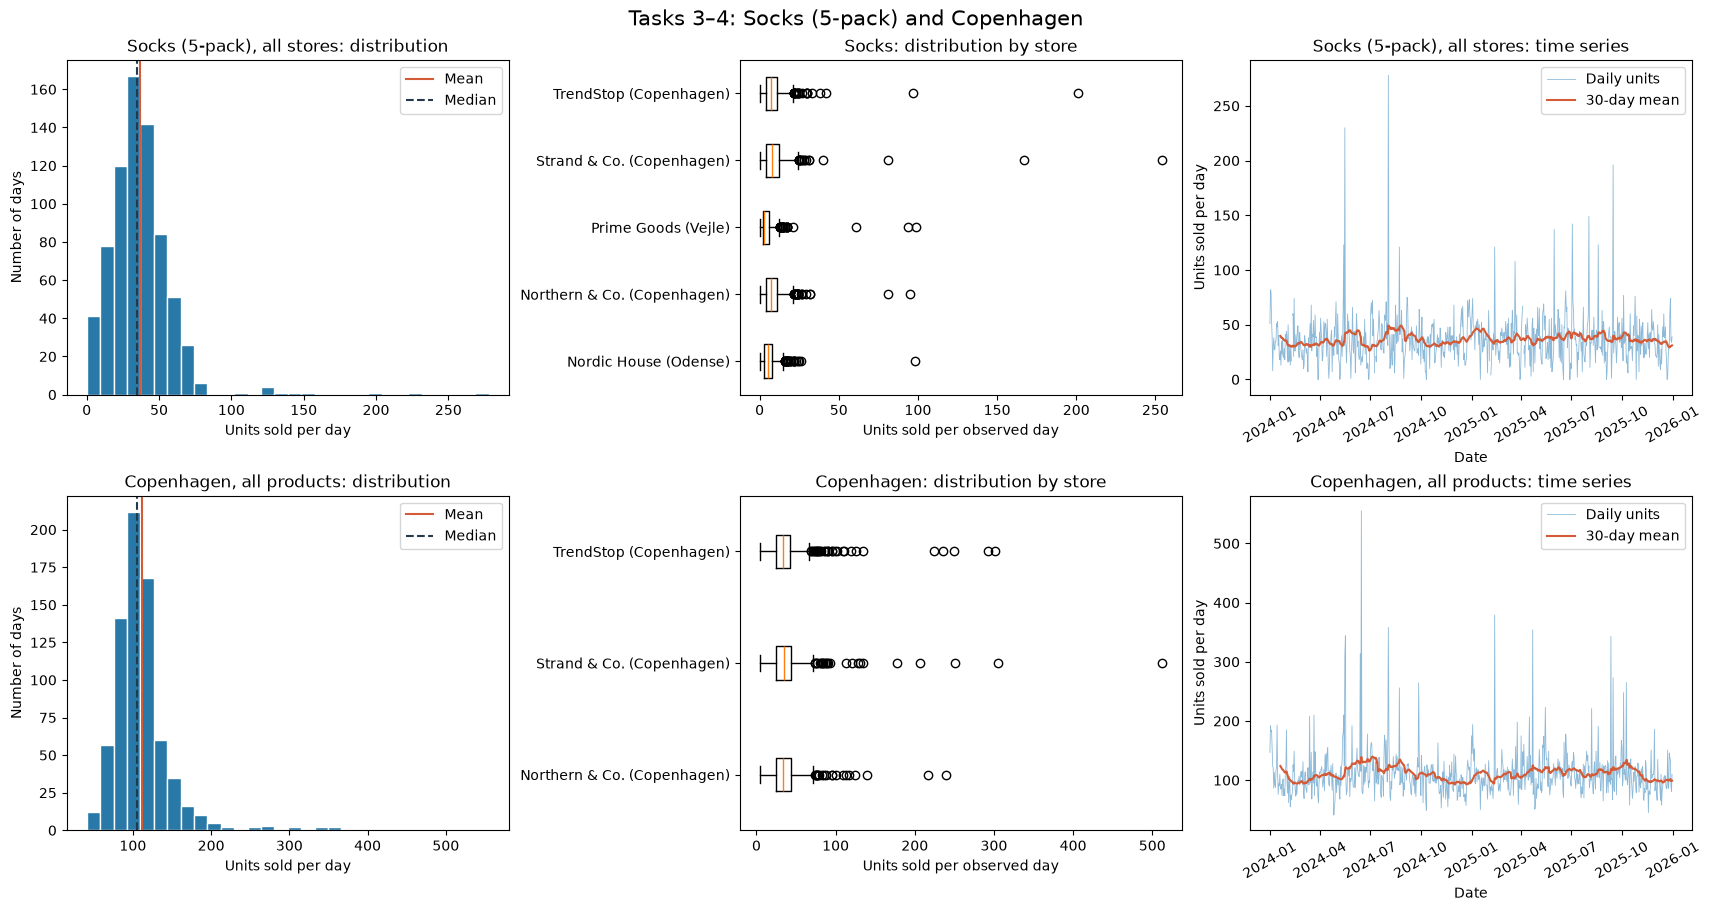

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9), constrained_layout=True)

for row, series, title in [(0, product_daily_all, 'Socks (5-pack), all stores'),
                           (1, location_daily_all, 'Copenhagen, all products')]:
    axes[row, 0].hist(series.dropna(), bins=30, color='#2878A8', edgecolor='white')
    axes[row, 0].axvline(series.mean(), color='#D45B37', label='Mean')
    axes[row, 0].axvline(series.median(), color='#25394B', linestyle='--', label='Median')
    axes[row, 0].set(title=f'{title}: distribution', xlabel='Units sold per day', ylabel='Number of days')
    axes[row, 0].legend()
    axes[row, 2].plot(series.index, series, linewidth=.6, alpha=.5, label='Daily units')
    axes[row, 2].plot(series.index, series.rolling(30, min_periods=20).mean(), color='#D45B37', label='30-day mean')
    axes[row, 2].set(title=f'{title}: time series', xlabel='Date', ylabel='Units sold per day')
    axes[row, 2].tick_params(axis='x', rotation=30)
    axes[row, 2].legend()


axes[0, 1].boxplot([product_daily_stores[s].dropna() for s in store_ids], tick_labels=store_ids,
                    orientation='horizontal')

axes[0, 1].set(title='Socks: distribution by store', xlabel='Units sold per observed day')

axes[1, 1].boxplot([location_daily_stores[s].dropna() for s in location_daily_stores],
                    tick_labels=location_daily_stores.columns,
                    orientation='horizontal')
axes[1, 1].set(title='Copenhagen: distribution by store', xlabel='Units sold per observed day')

fig.suptitle('Tasks 3–4: Socks (5-pack) and Copenhagen', fontsize=15)

plt.show()

# Performing EDA and figuring out insights from provided data

using EDA, we can figure out patterns that are present in dataset before building a model.


we will summarise record units and revenue by product, family, store, and location. 

we are also including price and catalogue-based total-profit boundaries to differentiate selling many cheap items from selling fewer expensive products. The revelue is additive, prices and profit margins are not summed together. 

we are comparing stores by their average recorded revenue per active day. 

In [20]:
product_summary = sales.groupby(['SKU', 'Product Name', 'Product Family']).agg(
    Units=('Sales Quantity', 'sum'), Revenue_DKK=('Revenue', 'sum'),
    Price_DKK=('Sale Price', 'first'), GP_lower_DKK=('Gross profit lower', 'sum'),
    GP_upper_DKK=('Gross profit upper', 'sum')).sort_values('Revenue_DKK', ascending=False)


family_summary = sales.groupby('Product Family').agg(
    Units=('Sales Quantity', 'sum'), Revenue_DKK=('Revenue', 'sum'),
    GP_lower_DKK=('Gross profit lower', 'sum'), GP_upper_DKK=('Gross profit upper', 'sum'))


family_summary['Revenue share (%)'] = family_summary['Revenue_DKK'] / sales['Revenue'].sum() * 100

family_summary['Average realised price DKK/unit'] = family_summary['Revenue_DKK'] / family_summary['Units']

store_summary = sales.groupby('Store ID').agg(
    Units=('Sales Quantity', 'sum'), Revenue_DKK=('Revenue', 'sum'),
    Invoices=('Invoice Number', 'nunique'), Recorded_days=('Date', 'nunique'))

store_summary['Revenue DKK/recorded day'] = store_summary['Revenue_DKK'] / store_summary['Recorded_days']


location_summary = sales.groupby('Store Location').agg(
    Stores=('Store ID', 'nunique'), Units=('Sales Quantity', 'sum'), Revenue_DKK=('Revenue', 'sum'))


display(product_summary)

display(family_summary.sort_values('Revenue_DKK', ascending=False))

display(store_summary.sort_values('Revenue_DKK', ascending=False))

display(location_summary)

display(Markdown(f"Across all usable recorded lines, Urban Trends sold **{sales['Sales Quantity'].sum():,} units**, generating **{sales['Revenue'].sum():,.0f} DKK**. Catalogue-based gross profit is between **{sales['Gross profit lower'].sum():,.0f} and {sales['Gross profit upper'].sum():,.0f} DKK**"))

,,,Units,Revenue_DKK,Price_DKK,GP_lower_DKK,GP_upper_DKK
SKU,Product Name,Product Family,,,,,
7,Socks (5-pack),Apparel,26821,4023150,150,2816205,2816205
27,Phone Case,Electronics,12075,3018750,250,1932000,1932000
36,Throw Blanket,Home,7350,2940000,400,2058000,2058000
63,Camping Tent,Sports & Outdoors,3147,2832300,900,1416150,1416150
29,HDMI Cable,Electronics,13365,2673000,200,2004750,2004750
189,Portable Heater,Tools & Machinery,5621,2529450,450,1517670,1517670
190,Extension Cord,Tools & Machinery,15033,2254950,150,1277805,1277805
58,Hiking Backpack,Sports & Outdoors,2520,2016000,800,1008000,1134000
164,Pull-Up Bar,Fitness Equipment,8988,1348200,150,808920,808920


,Units,Revenue_DKK,GP_lower_DKK,GP_upper_DKK,Revenue share (%),Average realised price DKK/unit
Product Family,,,,,,
Electronics,25440,5691750,3936750,3936750,23.143404,223.732311
Sports & Outdoors,5667,4848300,2424150,2550150,19.713826,855.532028
Tools & Machinery,20654,4784400,2795475,2795475,19.454000,231.645202
Apparel,26821,4023150,2816205,2816205,16.358657,150.000000
Home,7350,2940000,2058000,2058000,11.954427,400.000000
Fitness Equipment,8988,1348200,808920,808920,5.481959,150.000000
Office Supplies,19152,957600,574560,574560,3.893728,50.000000


,Units,Revenue_DKK,Invoices,Recorded_days,Revenue DKK/recorded day
Store ID,,,,,
Strand & Co. (Copenhagen),27749,5967000,7665,731,8162.790698
Northern & Co. (Copenhagen),26787,5805550,7682,731,7941.928865
TrendStop (Copenhagen),26856,5760300,7430,731,7880.027360
Nordic House (Odense),18800,4034750,5443,729,5534.636488
Prime Goods (Vejle),13880,3025800,3932,728,4156.318681


,Stores,Units,Revenue_DKK
Store Location,,,
Copenhagen,3,81392,17532850
Odense,1,18800,4034750
Vejle,1,13880,3025800


Across all usable recorded lines, Urban Trends sold **114,072 units**, generating **24,593,400 DKK**. Catalogue-based gross profit is between **15,414,060 and 15,540,060 DKK**

Let's find out sales rise of fall by months, 
compare year 2024 and 2025 by totals and average units 
we will also analyse which days of the week seel more mean units


since we only have data from 2024 and 2025, only 2 years, thiis is just descriptive evidence and not a proof of seasonal/holiday effects

In [21]:
families = sorted(sales['Product Family'].unique())

# daily 
family_daily_recorded = (sales.groupby(['Date', 'Product Family'])['Sales Quantity'].sum()
                         .unstack('Product Family').reindex(index=calendar, columns=families).fillna(0))

family_daily = family_daily_recorded.loc[complete_dates]

total_daily_complete = family_daily.sum(axis=1)


# monthly
monthly_revenue = (sales.groupby([pd.Grouper(key='Date', freq='MS'), 'Product Family'])['Revenue'].sum()
                   .unstack('Product Family').reindex(columns=families).fillna(0))


# yearly 
year_summary = sales.groupby(sales['Date'].dt.year).agg(Units=('Sales Quantity', 'sum'),
                                                       Revenue_DKK=('Revenue', 'sum'))
year_daily = total_daily_complete.groupby(total_daily_complete.index.year).agg(['count', 'mean'])
year_summary = year_summary.join(year_daily.rename(columns={'count': 'Complete dates', 'mean': 'Mean units/complete day'}))
display(year_summary)

# days of the week 
weekday_names = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday = total_daily_complete.groupby(total_daily_complete.index.dayofweek).agg(['count', 'mean', 'std'])
weekday.index = [weekday_names[i] for i in weekday.index]
display(weekday)




,Units,Revenue_DKK,Complete dates,Mean units/complete day
Date,,,,
2024,56966,12288700,364,155.821429
2025,57106,12304700,362,156.621547


,count,mean,std
Monday,105,153.800000,34.207343
Tuesday,104,155.201923,45.516322
Wednesday,104,158.086538,42.157152
Thursday,104,158.384615,53.685403
Friday,103,154.786408,45.329869
Saturday,102,163.598039,63.506491
Sunday,104,149.836538,30.766932


plotting monthly revenue by product family, comparing revenue by different family, mean daily units, and store revenue 

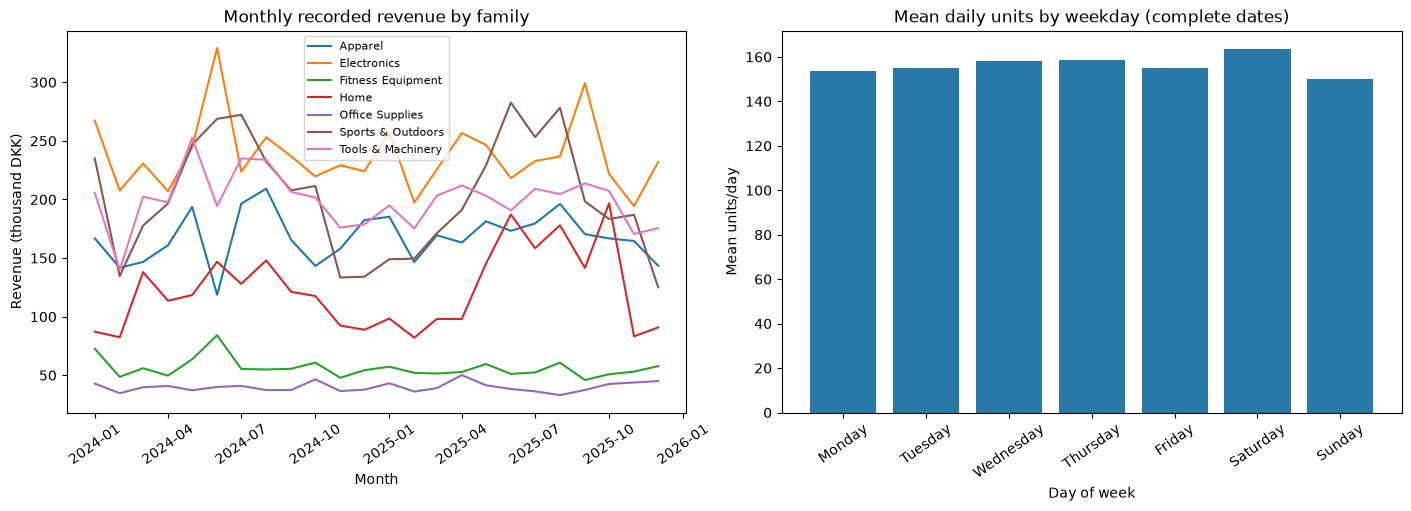

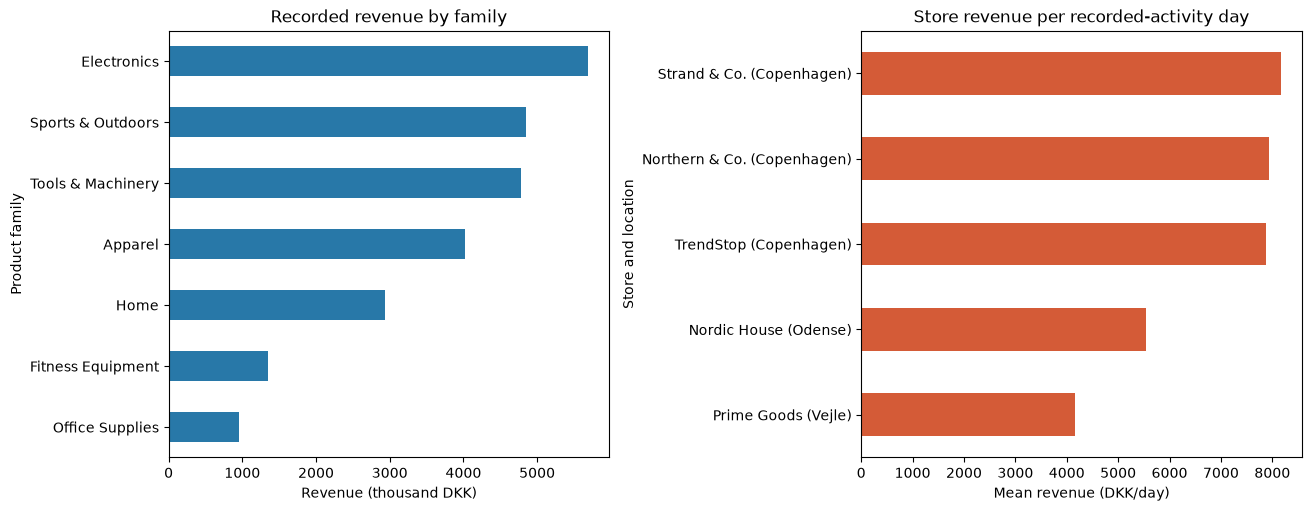

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for family in families:
    axes[0].plot(monthly_revenue.index, monthly_revenue[family] / 1000, label=family)
axes[0].set(title='Monthly recorded revenue by family', xlabel='Month', ylabel='Revenue (thousand DKK)')
axes[0].tick_params(axis='x', rotation=35)
axes[0].legend(fontsize=8)
axes[1].bar(weekday.index, weekday['mean'], color='#2878A8')
axes[1].set(title='Mean daily units by weekday (complete dates)', xlabel='Day of week', ylabel='Mean units/day')
axes[1].tick_params(axis='x', rotation=35)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
family_summary.sort_values('Revenue_DKK')['Revenue_DKK'].div(1000).plot.barh(ax=axes[0], color='#2878A8')
axes[0].set(title='Recorded revenue by family', xlabel='Revenue (thousand DKK)', ylabel='Product family')
store_summary.sort_values('Revenue DKK/recorded day')['Revenue DKK/recorded day'].plot.barh(ax=axes[1], color='#D45B37')
axes[1].set(title='Store revenue per recorded-activity day', xlabel='Mean revenue (DKK/day)', ylabel='Store and location')
plt.show()

In [25]:
unit_leader = family_summary['Units'].idxmax() 
# note: idxmax() is used for the index label of the first occurrence of the largest value

revenue_leader = family_summary['Revenue_DKK'].idxmax()
top_product = product_summary['Revenue_DKK'].idxmax()[1]
top_weekday = weekday['mean'].idxmax()
revenue_2025 = float(year_summary.loc[2025, 'Revenue_DKK'])
revenue_2024 = float(year_summary.loc[2024, 'Revenue_DKK'])

daily_units_2025 = float(year_summary.loc[2025, 'Mean units/complete day'])
daily_units_2024 = float(year_summary.loc[2024, 'Mean units/complete day'])

growth = 100 * (revenue_2025 / revenue_2024 - 1)

daily_growth = 100 * (daily_units_2025 / daily_units_2024 - 1)
display(Markdown(f'''
**Observed findings**

- **{unit_leader}** leads unit volume ({family_summary.loc[unit_leader, 'Units']:,.0f} units), while **{revenue_leader}** leads revenue ({family_summary.loc[revenue_leader, 'Revenue_DKK']:,.0f} DKK). Unit volume alone is insufficient for prioritising revenue.
- **{top_product}** is the highest-revenue individual product. Review both its availability and its gross-profit contribution before prioritising stock.
- Sports & Outdoors generates **{family_summary.loc['Sports & Outdoors', 'Revenue_DKK']:,.0f} DKK** from **{family_summary.loc['Sports & Outdoors', 'Units']:,.0f} units**. Its relatively high unit prices explain why low volume can still produce substantial revenue.
- **{top_weekday}** has the highest observed mean daily unit sales. This can inform a staffing/replenishment investigation, but does not explain why the difference exists.
- Recorded revenue changed **{growth:+.2f}%** from 2024 to 2025. Average units on complete dates changed **{daily_growth:+.2f}%**. Totals and daily rates measure different things.
- Copenhagen combines three stores, whereas Odense and Vejle each have one in these data. City totals therefore mix location effects with store count.

**Recommendations supported by this exploration**

1. Investigate the largest flagged invoice lines with the source system before changing them; use the sensitivity results to judge their impact.
2. Prioritise availability reviews using units, revenue, gross profit, and variability together. High sales do not by themselves justify a precise reorder quantity.
3. Obtain supplier-linked purchasing records before reporting exact backpack profitability. Its two suppliers trade off catalogue cost, lead time, and stated emissions.
4. Collect opening calendars, stockouts, inventory movements, footfall, and promotion data before attributing store or seasonal differences to causes.
'''))


**Observed findings**

- **Apparel** leads unit volume (26,821 units), while **Electronics** leads revenue (5,691,750 DKK). Unit volume alone is insufficient for prioritising revenue.
- **Socks (5-pack)** is the highest-revenue individual product. Review both its availability and its gross-profit contribution before prioritising stock.
- Sports & Outdoors generates **4,848,300 DKK** from **5,667 units**. Its relatively high unit prices explain why low volume can still produce substantial revenue.
- **Saturday** has the highest observed mean daily unit sales. This can inform a staffing/replenishment investigation, but does not explain why the difference exists.
- Recorded revenue changed **+0.13%** from 2024 to 2025. Average units on complete dates changed **+0.51%**. Totals and daily rates measure different things.
- Copenhagen combines three stores, whereas Odense and Vejle each have one in these data. City totals therefore mix location effects with store count.

**Recommendations supported by this exploration**

1. Investigate the largest flagged invoice lines with the source system before changing them; use the sensitivity results to judge their impact.
2. Prioritise availability reviews using units, revenue, gross profit, and variability together. High sales do not by themselves justify a precise reorder quantity.
3. Obtain supplier-linked purchasing records before reporting exact backpack profitability. Its two suppliers trade off catalogue cost, lead time, and stated emissions.
4. Collect opening calendars, stockouts, inventory movements, footfall, and promotion data before attributing store or seasonal differences to causes.


# Cluster produc families by quantity and revenue 

we will use k-means from scipy for clustering and we will use k=3 for 3 clusters

In [28]:
from scipy.cluster.vq import kmeans2

In [30]:
features = family_summary[['Units', 'Revenue_DKK']].astype(float)

z = (features - features.mean()) / features.std(ddof=0)

k = 3

best = None

for seed in range(30):
    rng = np.random.default_rng(seed)
    initial = z.to_numpy()[rng.choice(len(z), size=k, replace=False)]
    centers, labels = kmeans2(z.to_numpy(), initial, iter=100, minit='matrix', missing='raise')
    inertia = float(((z.to_numpy() - centers[labels]) ** 2).sum())
    if best is None or inertia < best[0]:
        best = (inertia, centers, labels)

cluster_table = features.copy()

cluster_table['Cluster'] = best[2] + 1

display(cluster_table.sort_values(['Cluster', 'Units']))

print(f'k = {k}; best inertia on standardised features = {best[0]:.3f}')

display(cluster_table.groupby('Cluster').agg(Families=('Units', 'size'),
                                            Mean_units=('Units', 'mean'), Mean_revenue_DKK=('Revenue_DKK', 'mean')))



,Units,Revenue_DKK,Cluster
Product Family,,,
Fitness Equipment,8988.0,1348200.0,1
Office Supplies,19152.0,957600.0,1
Tools & Machinery,20654.0,4784400.0,2
Electronics,25440.0,5691750.0,2
Apparel,26821.0,4023150.0,2
Sports & Outdoors,5667.0,4848300.0,3
Home,7350.0,2940000.0,3


k = 3; best inertia on standardised features = 2.262


,Families,Mean_units,Mean_revenue_DKK
Cluster,,,
1,2,14070.0,1152900.0
2,3,24305.0,4833100.0
3,2,6508.5,3894150.0


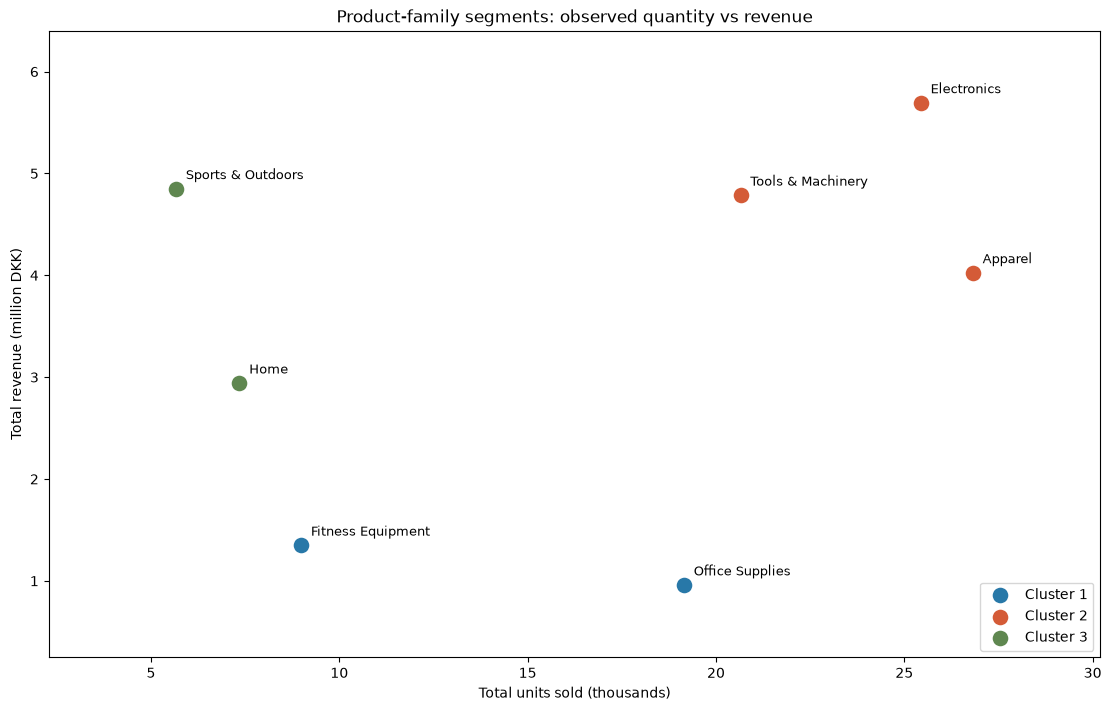

**Interpretation:** Office Supplies has substantial volume but relatively little revenue because its marker set costs 50 DKK. Sports & Outdoors has relatively low volume but high revenue because backpacks and tents cost 800–900 DKK. Revenue and units are related through the product mix and prices; they are not independent measures.

In [31]:
# plotting clusters
fig, ax = plt.subplots(figsize=(11, 7), constrained_layout=True)

colors = ['#2878A8', '#D45B37', '#5F8750']
for cluster in sorted(cluster_table['Cluster'].unique()):
    group = cluster_table.loc[cluster_table['Cluster'].eq(cluster)]
    ax.scatter(group['Units'] / 1000, group['Revenue_DKK'] / 1_000_000,
               s=150, color=colors[cluster - 1], label=f'Cluster {cluster}', edgecolor='white')
for family, row in cluster_table.iterrows():
    ax.annotate(family, (row['Units'] / 1000, row['Revenue_DKK'] / 1_000_000),
                xytext=(7, 7), textcoords='offset points', fontsize=9)
ax.set(title='Product-family segments: observed quantity vs revenue',
       xlabel='Total units sold (thousands)', ylabel='Total revenue (million DKK)')
ax.margins(x=.16, y=.15)
ax.legend(loc='lower right')
plt.show()
display(Markdown('**Interpretation:** Office Supplies has substantial volume but relatively little revenue because its marker set costs 50 DKK. Sports & Outdoors has relatively low volume but high revenue because backpacks and tents cost 800–900 DKK. Revenue and units are related through the product mix and prices; they are not independent measures.'))

# Calculate mean, standard deviation and coefficient of variation (CV) of the sales of the different product families. What can you learn about the demand patterns?

for each product family, we will sum the units by date across all stores to figure out the demand

then we will calculate the mean, daily units, standard deviation and CV


where CV = SD/mean x 100% 

higher CV = bigger variation compared to mean

In [32]:
def family_demand_summary(frame):
    daily = (frame.groupby(['Date', 'Product Family'])['Sales Quantity'].sum()
             .unstack('Product Family').reindex(index=calendar, columns=families).fillna(0)
             .loc[complete_dates])
    table = pd.DataFrame({'Days': daily.count(), 'Mean units/day': daily.mean(),
                          'Sample SD units/day': daily.std(ddof=1)})
    table['CV (%)'] = 100 * table['Sample SD units/day'] / table['Mean units/day'].replace(0, np.nan)
    return daily, table

family_daily, demand_main = family_demand_summary(sales)



family_daily_sensitivity, demand_sensitivity = family_demand_summary(sales_sensitivity)

demand_comparison = demand_main.join(demand_sensitivity[['Mean units/day', 'Sample SD units/day', 'CV (%)']],
                                    rsuffix=' without rare sales')


display(demand_comparison.sort_values('CV (%)', ascending=False))


,Days,Mean units/day,Sample SD units/day,CV (%),Mean units/day without rare sales,Sample SD units/day without rare sales,CV (%) without rare sales
Product Family,,,,,,,
Home,726,10.070248,11.683021,116.015231,9.128099,4.525649,49.579315
Fitness Equipment,726,12.287879,9.683319,78.803829,11.732782,5.184082,44.184589
Electronics,726,34.822314,26.729761,76.760438,31.936639,10.913521,34.172416
Sports & Outdoors,726,7.758953,5.914426,76.227115,7.359504,3.591786,48.804722
Apparel,726,36.761708,22.965695,62.471784,34.856749,16.068092,46.097506
Office Supplies,726,26.238292,15.696596,59.823240,25.320937,11.640016,45.969925
Tools & Machinery,726,28.280992,16.278807,57.560948,26.994490,10.940969,40.530377


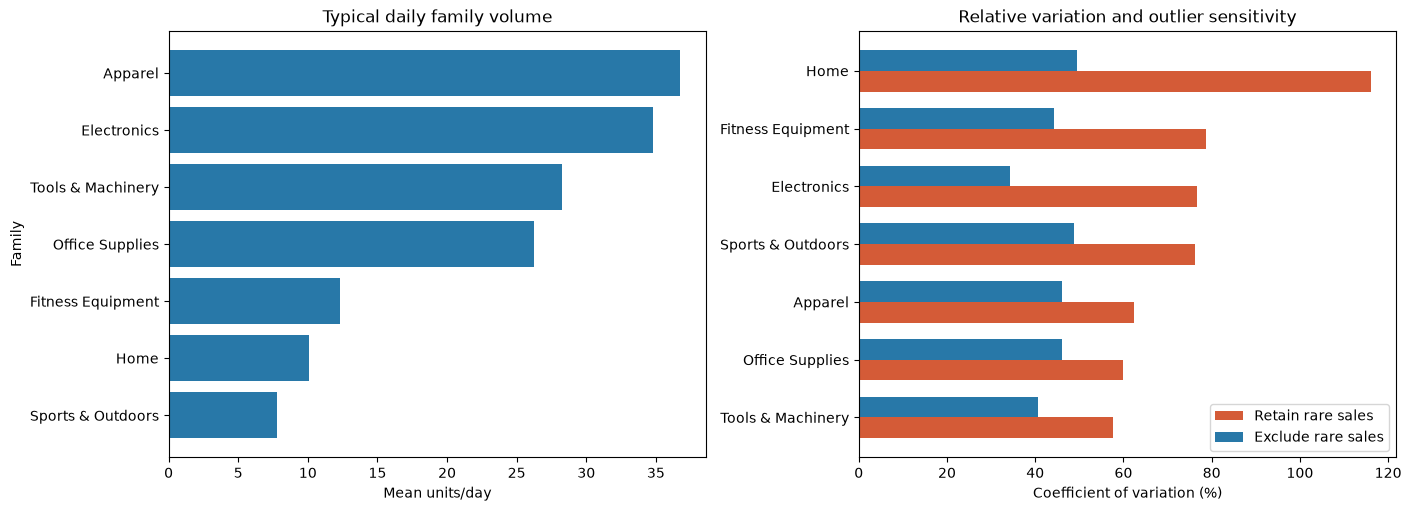

In [33]:
# plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
order = demand_main.sort_values('Mean units/day').index
axes[0].barh(order, demand_main.loc[order, 'Mean units/day'], color='#2878A8')
axes[0].set(title='Typical daily family volume', xlabel='Mean units/day', ylabel='Family')
order = demand_main.sort_values('CV (%)').index
y = np.arange(len(order))
axes[1].barh(y - .18, demand_main.loc[order, 'CV (%)'], height=.36, label='Retain rare sales', color='#D45B37')
axes[1].barh(y + .18, demand_sensitivity.loc[order, 'CV (%)'], height=.36, label='Exclude rare sales', color='#2878A8')
axes[1].set(yticks=y, yticklabels=order, title='Relative variation and outlier sensitivity', xlabel='Coefficient of variation (%)')
axes[1].legend()
plt.show()

highest_cv = demand_main['CV (%)'].idxmax()
lowest_cv = demand_main['CV (%)'].idxmin()
largest_cv_change = (demand_main['CV (%)'] - demand_sensitivity['CV (%)']).abs().idxmax()


### Demand interpretation

In [34]:
display(Markdown(f'''
**Demand interpretation**

- **{highest_cv}** has the highest main-scenario CV (**{demand_main.loc[highest_cv, 'CV (%)']:.2f}%**), so its recorded daily sales vary most relative to its mean.
- **{lowest_cv}** has the lowest main-scenario CV (**{demand_main.loc[lowest_cv, 'CV (%)']:.2f}%**), so it is comparatively steadier on this measure. It still has variation and is not necessarily easy to forecast.
- Excluding rare sales changes **{largest_cv_change}**'s CV most: from **{demand_main.loc[largest_cv_change, 'CV (%)']:.2f}%** to **{demand_sensitivity.loc[largest_cv_change, 'CV (%)']:.2f}%**. This demonstrates why an outlier policy affects operational conclusions.
- Families with high volume and relatively lower CV may support regular replenishment reviews. More variable families warrant closer investigation of seasonality, bulk purchases, and service-level needs. A numerical reorder point additionally requires store-level inventory and lead-time assumptions.
'''))


**Demand interpretation**

- **Home** has the highest main-scenario CV (**116.02%**), so its recorded daily sales vary most relative to its mean.
- **Tools & Machinery** has the lowest main-scenario CV (**57.56%**), so it is comparatively steadier on this measure. It still has variation and is not necessarily easy to forecast.
- Excluding rare sales changes **Home**'s CV most: from **116.02%** to **49.58%**. This demonstrates why an outlier policy affects operational conclusions.
- Families with high volume and relatively lower CV may support regular replenishment reviews. More variable families warrant closer investigation of seasonality, bulk purchases, and service-level needs. A numerical reorder point additionally requires store-level inventory and lead-time assumptions.
